# 1-01 일별 NXT vs KRX 거래량 비중 — 종목별·시장별로 NXT가 얼마나 가져갔나

**질문 예시:** "어제 넥스트레이드 거래량이 KRX 대비 얼마나 됐어?", "NXT 비중이 제일 높은 종목은?", "코스닥이 코스피보다 NXT 비중이 높아?"

원본은 `krxnewsscrap`의 `krxnxtplotly.py`(Streamlit)·`krxvsnxt.ipynb`입니다. 그 아이디어를 패키지 호출로 다시 짜고,
무엇과 무엇을 비교하는지 분명히 했습니다.

| 항목 | 출처 |
|---|---|
| NXT 거래량·거래대금 | `nxt_data_api` — `regular_market` + `closing_price` + `block_trade` (세 화면 합계) |
| KRX 거래량·거래대금·시가총액 | `krx_data_api` `all_stock_price` ([12001] 전종목시세, JSON) |
| 조인 키 | 6자리 단축코드 (NXT `isuSrdCd`의 앞 `A` 제거 = KRX `ISU_SRT_CD`) |

**두 거래소의 숫자는 서로 배타적입니다.** KRX 거래량은 KRX에서 체결된 것만, NXT 거래량은 NXT에서 체결된 것만 담습니다
(`docs/NXT_거래현황_API_정리.md` §2.1). 그래서 "전체 거래량"은 둘을 더한 값입니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/nxt-data-api/blob/main/scenarios/1_nxt_vs_krx/01_daily_share.ipynb)

## 0. 준비
넥스트레이드(NXT) 데이터는 로그인이 필요 없지만, KRX 정보데이터시스템은 2026-09부터 로그인해야 합니다. Colab 왼쪽 🔑(Secrets)에 `KRX_ID`, `KRX_PW`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 패키지 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib \
        git+https://github.com/beaten-by-the-market/nxt-data-api.git \
        git+https://github.com/beaten-by-the-market/krx-data-api.git

In [2]:
# ── NXT·KRX 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# NXT(넥스트레이드): nxt_data_api — 로그인 불필요.
# KRX(정보데이터시스템): krx_data_api — 2026-09부터 로그인 필요.
#   Colab: 왼쪽 🔑(Secrets)에 KRX_ID, KRX_PW 를 넣고 "노트북 액세스"를 켜세요. 값은 출력하지 않습니다.
#   로컬: 환경변수 → 작업 폴더 .env → (편집 가능 설치라면) krx-data-api 레포의 .env 순서로 찾습니다.
import os, sys, time
from datetime import date, datetime, timedelta

import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    for _k in ("KRX_ID", "KRX_PW"):
        try:
            _v = userdata.get(_k)
            if _v:
                os.environ[_k] = _v
        except Exception as _e:  # SecretNotFoundError / NotebookAccessError
            print(f"Colab Secrets에서 {_k}를 읽지 못했습니다 ({type(_e).__name__}). 🔑에 등록하고 액세스를 켜세요.")

from nxt_data_api import fetch as nxt_fetch, fetch_range as nxt_fetch_range
from krx_data_api import fetch as krx_fetch
from krx_data_api.daily_snapshots import trading_days  # KRX 매매거래일 목록 (삼성전자 시세추이의 일자)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)

MARKETS = ["KOSPI", "KOSDAQ"]  # NXT는 코넥스 종목을 거래하지 않습니다


def _num(s):
    """'1,234' / '-' / '' 같은 문자열 → 숫자 (없으면 NaN)."""
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip()
                         .replace({"-": None, "": None, "None": None, "nan": None}), errors="coerce")


def _as_list(dates):
    return [dates] if isinstance(dates, (str, date, datetime)) else list(dates)


def nxt_volume(dates, pause=0.1):
    """NXT 종목별·일별 거래량/거래대금. dates: 'YYYYMMDD' 하나 또는 목록.

    NXT 하루 총거래량 = 정규시장(regular_market) + 종가매매(closing_price) + 대량·바스켓(block_trade).
    세 화면은 서로 겹치지 않습니다(block_trade 의 isuAccTdQty 와 원 단위로 일치, 2026-02-06 삼성전자).
    거래대금은 정규시장 + 종가매매만 있습니다(대량·바스켓 화면에 거래대금이 없음).
    """
    days = [pd.Timestamp(d).strftime("%Y%m%d") for d in _as_list(dates)]
    kw = dict(dates=days, pause=pause)
    reg = nxt_fetch_range("regular_market", days[0], days[-1], **kw)
    if reg.empty:
        return pd.DataFrame()
    clo = nxt_fetch_range("closing_price", days[0], days[-1], **kw)
    blk = nxt_fetch_range("block_trade", days[0], days[-1], **kw)

    def key(df):
        return df.assign(일자=df["aggDd"].astype(str), 코드=df["isuSrdCd"].str[1:])  # 'A005930' → '005930'

    out = key(reg).rename(columns={"isuAbwdNm": "종목명", "mktNm": "시장", "accTdQty": "NXT정규량",
                                   "accTrval": "NXT정규대금", "cptrTrdPmsnCdNm": "NXT거래가능",
                                   "trdIpsbRsn": "NXT거래불가사유"})
    out = out[["일자", "코드", "종목명", "시장", "NXT정규량", "NXT정규대금", "NXT거래가능", "NXT거래불가사유"]]
    if not clo.empty:
        c = key(clo).rename(columns={"accTdQty": "NXT종가량", "accTrval": "NXT종가대금"})
        extra = set(zip(c["일자"], c["코드"])) - set(zip(out["일자"], out["코드"]))
        if extra:
            print(f"주의: 종가매매에만 있고 정규시장 목록에 없는 종목 {len(extra)}건 (합계에서 빠짐)")
        out = out.merge(c[["일자", "코드", "NXT종가량", "NXT종가대금"]], on=["일자", "코드"], how="left")
    else:
        out["NXT종가량"], out["NXT종가대금"] = 0, 0
    if not blk.empty:
        b = key(blk).assign(NXT대량량=lambda x: _num(x["bltdAccTdQty"]))
        b = b.groupby(["일자", "코드"], as_index=False)["NXT대량량"].sum()
        out = out.merge(b, on=["일자", "코드"], how="left")
    else:
        out["NXT대량량"] = 0
    for c in ("NXT정규량", "NXT정규대금", "NXT종가량", "NXT종가대금", "NXT대량량"):
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0)
    out["NXT거래량"] = out["NXT정규량"] + out["NXT종가량"] + out["NXT대량량"]
    out["NXT거래대금"] = out["NXT정규대금"] + out["NXT종가대금"]
    # 정규시장 스냅샷 적재 시각 (일자별 최댓값). 20시 이후면 애프터마켓까지 들어간 값입니다
    out.attrs["loaded_at"] = reg.groupby("aggDd")["registDt"].max().dt.strftime("%Y-%m-%d %H:%M").to_dict()
    out.attrs["empty_dates"] = reg.attrs.get("empty_dates", [])
    return out


def krx_prices(day):
    """KRX [12001] 전종목시세 하루치 (all_stock_price, JSON). 영문 코드 컬럼을 명시적으로 한글로 바꿉니다.
    거래량·거래대금은 KRX에서 체결된 것만입니다(NXT 미포함)."""
    day = pd.Timestamp(day).strftime("%Y%m%d")
    raw = krx_fetch("all_stock_price", trdDd=day)
    df = pd.DataFrame({
        "일자": day,
        "코드": raw["ISU_SRT_CD"].astype(str).str.strip(),      # 6자리 단축코드
        "KRX종목명": raw["ISU_ABBRV"].astype(str).str.strip(),
        "KRX시장": raw["MKT_NM"].astype(str).str.strip().replace({"KOSDAQ GLOBAL": "KOSDAQ"}),
        "소속부": raw["SECT_TP_NM"].astype(str).str.strip() if "SECT_TP_NM" in raw else "",
        "KRX종가": _num(raw["TDD_CLSPRC"]),
        "KRX거래량": _num(raw["ACC_TRDVOL"]),
        "KRX거래대금": _num(raw["ACC_TRDVAL"]),
        "시가총액": _num(raw["MKTCAP"]),
    })
    if df["KRX거래량"].notna().sum() == 0:  # 휴장일은 값이 전부 '-' 로 옵니다
        raise ValueError(f"{day}: KRX 거래 데이터가 없습니다(휴장일이거나 아직 집계 전).")
    return df


def krx_range(dates, pause=0.3):
    """여러 거래일의 KRX 전종목시세를 이어 붙입니다 (하루 1회 호출)."""
    days = _as_list(dates)
    parts = []
    for i, d in enumerate(days):
        parts.append(krx_prices(d))
        if pause and i < len(days) - 1:
            time.sleep(pause)
    return pd.concat(parts, ignore_index=True)


def compare(nxt, krx):
    """NXT·KRX를 (일자, 6자리 코드)로 outer join 하고 비중을 계산합니다.

    거래소: 'NXT·KRX' (둘 다 있음) / 'KRX만' (NXT 거래 대상이 아닌 종목) / 'NXT만' (KRX 목록에 없음 — 보통 0건)
    NXT점유율(%)  = NXT / (NXT + KRX) × 100   ← 두 거래소 합계 중 NXT 몫 (0~100)
    NXT/KRX(%)   = NXT / KRX × 100           ← 원본 앱의 '비중'. KRX보다 많으면 100을 넘습니다
    """
    df = krx.merge(nxt, on=["일자", "코드"], how="outer", indicator=True)
    df["거래소"] = df["_merge"].map({"both": "NXT·KRX", "left_only": "KRX만", "right_only": "NXT만"})
    df["종목명"] = df["종목명"].fillna(df["KRX종목명"]) if "종목명" in df else df["KRX종목명"]
    df["시장"] = df["KRX시장"].fillna(df.get("시장"))
    df["NXT종목"] = df["거래소"] != "KRX만"
    for c in ("NXT거래량", "NXT거래대금", "KRX거래량", "KRX거래대금"):
        df[c] = df[c].fillna(0)
    df["합계거래량"] = df["NXT거래량"] + df["KRX거래량"]
    df["합계거래대금"] = df["NXT거래대금"] + df["KRX거래대금"]
    df["NXT점유율(%)"] = (df["NXT거래량"] / df["합계거래량"].replace(0, np.nan) * 100).round(2)
    df["NXT대금점유율(%)"] = (df["NXT거래대금"] / df["합계거래대금"].replace(0, np.nan) * 100).round(2)
    df["NXT/KRX(%)"] = (df["NXT거래량"] / df["KRX거래량"].replace(0, np.nan) * 100).round(2)
    return df.drop(columns=["_merge", "KRX종목명", "KRX시장"]).reset_index(drop=True)


def share_summary(df, by=("시장",)):
    """그룹별 합계와 비중. 두 모집단을 나란히 보여 줍니다.
    - 'NXT 거래종목': NXT에서 거래된 종목만 (NXT 종목 vs 같은 종목의 KRX 거래)
    - '시장 전체'   : KOSPI·KOSDAQ 전 종목 (NXT 미거래 종목의 KRX 거래까지 분모에 포함)"""
    by = list(by)
    d = df[df["시장"].isin(MARKETS)]
    rows = []
    for universe, sub in (("NXT 거래종목", d[d["NXT종목"]]), ("시장 전체", d)):
        groups = list(sub.groupby(by))
        # 마지막 기준(보통 '시장')을 합친 '합계' 행도 붙입니다
        if len(by) == 1:
            groups.append((("합계",), sub))
        else:
            groups += [((*(k if isinstance(k, tuple) else (k,)), "합계"), g) for k, g in sub.groupby(by[:-1])]
        for keys, g in groups:
            keys = keys if isinstance(keys, tuple) else (keys,)
            n, k, nv, kv = g["NXT거래량"].sum(), g["KRX거래량"].sum(), g["NXT거래대금"].sum(), g["KRX거래대금"].sum()
            rows.append({"모집단": universe, **dict(zip(by, keys)), "종목수": int(len(g)),
                         "NXT거래량": n, "KRX거래량": k,
                         "NXT점유율(%)": round(n / (n + k) * 100, 2) if n + k else np.nan,
                         "NXT/KRX(%)": round(n / k * 100, 2) if k else np.nan,
                         "NXT거래대금": nv, "KRX거래대금": kv,
                         "NXT대금점유율(%)": round(nv / (nv + kv) * 100, 2) if nv + kv else np.nan})
    return pd.DataFrame(rows)


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


def shares(v):
    """주 → '1.2억주' / '3,456만주'."""
    if v is None or pd.isna(v):
        return "-"
    return f"{v / 1e8:.2f}억주" if abs(v) >= 1e8 else f"{v / 1e4:,.0f}만주"


# 차트 색 (시장은 고정 순서: KOSPI 1번, KOSDAQ 2번 / 거래소는 NXT 강조색, KRX 중립 회색)
MKT_COLOR = {"KOSPI": "#2a78d6", "KOSDAQ": "#eb6834"}
NXT_COLOR, KRX_COLOR = "#6250d6", "#c3c2b7"

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("NXT·KRX 준비 완료", "(Colab)" if IN_COLAB else "(로컬)",
      "| KRX 계정:", "설정됨" if os.environ.get("KRX_ID") and os.environ.get("KRX_PW") else "없음 — KRX 호출이 거절됩니다")

NXT·KRX 준비 완료 (로컬) | KRX 계정: 설정됨


In [3]:
DAY = "20261124"        # 조회일 (매매거래일, YYYYMMDD)
MIN_VALUE = 100e8       # 종목 순위에 넣을 최소 합계 거래대금 (원). 거래가 거의 없는 종목의 극단값을 거릅니다
TOP_N = 20

## 1. 데이터 받기
NXT의 하루 거래는 화면 세 개로 나뉘어 있습니다. 서로 겹치지 않아서 **셋을 더해야 NXT 총거래량**이 됩니다.

| 화면 | 패키지 이름 | 담긴 거래 |
|---|---|---|
| 거래현황 > 정규시장 | `regular_market` | NXT 연속매매 체결분. 20:05에 집계된 스냅샷이라 애프터마켓(~20:00)까지 들어 있습니다 |
| 거래현황 > 종가매매 | `closing_price` | KRX 종가로 체결되는 종가매매 세션 (체결된 종목만 나옴) |
| 거래현황 > 대량·바스켓매매 | `block_trade` | 대량·바스켓매매 (있는 날만, 대개 0건). **거래대금 필드가 없습니다** |

KRX 쪽은 [12001] 전종목시세의 `ACC_TRDVOL`(거래량)·`ACC_TRDVAL`(거래대금)입니다.
2026-07-02부터 `all_stock_price`는 영문 코드 컬럼(`ISU_SRT_CD`, `ACC_TRDVOL` …)으로 오므로 헬퍼 `krx_prices()`가 컬럼을 하나씩 짝지어 바꿉니다.

In [4]:
nxt = nxt_volume(DAY)
krx = krx_prices(DAY)
print(f"NXT {len(nxt)}종목 (정규시장 적재 시각 {nxt.attrs['loaded_at'].get(DAY)}), KRX {len(krx)}종목")

session = pd.DataFrame({
    "거래량": [nxt["NXT정규량"].sum(), nxt["NXT종가량"].sum(), nxt["NXT대량량"].sum()],
    "거래대금": [nxt["NXT정규대금"].sum(), nxt["NXT종가대금"].sum(), np.nan],
}, index=["정규시장", "종가매매", "대량·바스켓"])
session["거래량 비중(%)"] = (session["거래량"] / session["거래량"].sum() * 100).round(3)
session.assign(거래량=session["거래량"].map(lambda v: f"{v:,.0f}주"), 거래대금=session["거래대금"].map(krw))

NXT 602종목 (정규시장 적재 시각 2026-11-24 20:05), KRX 2879종목


,거래량,거래대금,거래량 비중(%)
정규시장,"97,022,912주",12.4조,99.999
종가매매,"1,312주",1억,0.001
대량·바스켓,0주,-,0.000


## 2. 6자리 코드로 맞추기
KRX 전종목(코스피·코스닥·코넥스, 우선주 포함)과 NXT 거래종목을 outer join 합니다.
- **NXT·KRX**: 두 곳에서 모두 거래된 종목
- **KRX만**: NXT 거래 대상이 아닌 종목 (코넥스 전부, 대부분의 중소형주·우선주). NXT 거래량은 0으로 둡니다
- **NXT만**: KRX 목록에 없는 NXT 종목 — 정상이면 0건이어야 합니다

In [5]:
df = compare(nxt, krx)
print(df["거래소"].value_counts().to_string())
pd.crosstab(df["시장"], df["거래소"], margins=True, margins_name="합계")

거래소
KRX만       2277
NXT·KRX     602
NXT만          0


거래소,KRX만,NXT·KRX,합계
시장,,,
KONEX,107,0,107
KOSDAQ,1570,267,1837
KOSPI,600,335,935
합계,2277,602,2879


## 3. 시장별 요약 — 비중을 두 가지로 정의합니다
- **NXT점유율 = NXT ÷ (NXT + KRX)**: 두 거래소 합계 중 NXT 몫. 0~100%이며 이 노트북의 기본 지표입니다.
- **NXT/KRX = NXT ÷ KRX**: 원본 앱의 "비중(NXT/KRX)". KRX 대비 몇 %인지라서 100%를 넘을 수 있습니다.
  (점유율 p 와는 `NXT/KRX = p / (100 − p) × 100` 관계)

모집단도 둘로 나눕니다. **NXT 거래종목**은 NXT에서 거래되는 종목끼리만 비교한 값(원본 앱과 같은 기준)이고,
**시장 전체**는 NXT에서 거래되지 않는 종목의 KRX 거래까지 분모에 넣은 값(코넥스 제외)입니다.

In [6]:
summ = share_summary(df)
show = summ.copy()
for c in ("NXT거래량", "KRX거래량"):
    show[c] = show[c].map(shares)
for c in ("NXT거래대금", "KRX거래대금"):
    show[c] = show[c].map(krw)
show

,모집단,시장,종목수,NXT거래량,KRX거래량,NXT점유율(%),NXT/KRX(%),NXT거래대금,KRX거래대금,NXT대금점유율(%)
0,NXT 거래종목,KOSDAQ,267,"4,480만주","5,070만주",46.91,88.37,2.0조,2.3조,46.22
1,NXT 거래종목,KOSPI,335,"5,222만주","9,000만주",36.72,58.02,10.4조,14.1조,42.41
2,NXT 거래종목,합계,602,"9,702만주",1.41억주,40.81,68.96,12.4조,16.4조,42.98
3,시장 전체,KOSDAQ,1837,"4,480만주",4.42억주,9.21,10.14,2.0조,5.9조,25.20
4,시장 전체,KOSPI,935,"5,222만주",1.94억주,21.20,26.90,10.4조,15.8조,39.71
5,시장 전체,합계,2772,"9,702만주",6.36억주,13.24,15.25,12.4조,21.7조,36.34


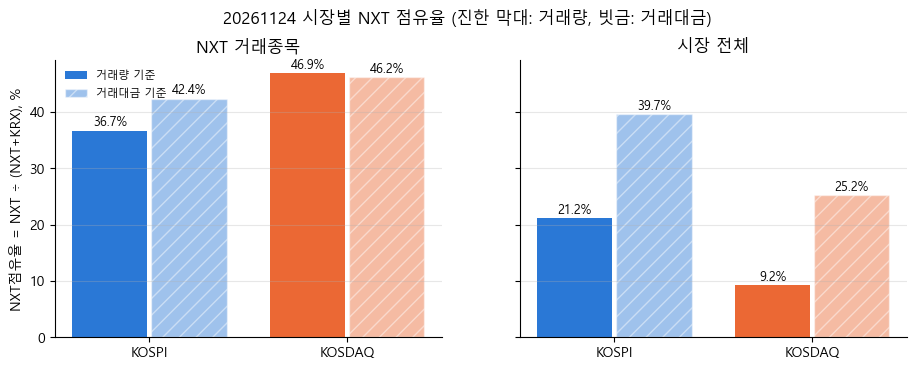

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, uni in zip(axes, ["NXT 거래종목", "시장 전체"]):
    s = summ[(summ["모집단"] == uni) & summ["시장"].isin(MARKETS)].set_index("시장").loc[MARKETS]
    x = np.arange(2)
    ax.bar(x - 0.2, s["NXT점유율(%)"], 0.38, color=[MKT_COLOR[m] for m in MARKETS], label="거래량 기준")
    ax.bar(x + 0.2, s["NXT대금점유율(%)"], 0.38, color=[MKT_COLOR[m] for m in MARKETS], alpha=0.45,
           hatch="//", edgecolor="white", label="거래대금 기준")
    for i, (a, b) in enumerate(zip(s["NXT점유율(%)"], s["NXT대금점유율(%)"])):
        ax.text(i - 0.2, a + 0.8, f"{a:.1f}%", ha="center", fontsize=9)
        ax.text(i + 0.2, b + 0.8, f"{b:.1f}%", ha="center", fontsize=9)
    ax.set_xticks(x, MARKETS); ax.set_title(f"{uni}"); ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("NXT점유율 = NXT ÷ (NXT+KRX), %")
axes[0].legend(loc="upper left", fontsize=8, frameon=False)
fig.suptitle(f"{DAY} 시장별 NXT 점유율 (진한 막대: 거래량, 빗금: 거래대금)", y=1.02)
plt.show()

## 4. 종목별 순위
합계 거래대금이 `MIN_VALUE`(기본 100억 원) 이상인 NXT 거래종목만 순위에 넣습니다.
거래가 거의 없는 종목은 몇 주만 체결돼도 점유율이 극단으로 튀기 때문입니다.

In [8]:
both = df[df["NXT종목"]].copy()
liquid = both[both["합계거래대금"] >= MIN_VALUE]
cols = ["코드", "종목명", "시장", "NXT거래량", "KRX거래량", "NXT점유율(%)", "NXT/KRX(%)", "NXT거래대금", "합계거래대금"]

def fmt(t):
    t = t[cols].copy()
    for c in ("NXT거래량", "KRX거래량"):
        t[c] = t[c].map(lambda v: f"{v:,.0f}")
    for c in ("NXT거래대금", "합계거래대금"):
        t[c] = t[c].map(krw)
    return t.reset_index(drop=True)

print(f"순위 대상 {len(liquid)} / NXT 거래종목 {len(both)}")
print(f"▶ NXT점유율 상위 {TOP_N}")
fmt(liquid.sort_values("NXT점유율(%)", ascending=False).head(TOP_N))

순위 대상 191 / NXT 거래종목 602
▶ NXT점유율 상위 20


,코드,종목명,시장,NXT거래량,KRX거래량,NXT점유율(%),NXT/KRX(%),NXT거래대금,합계거래대금
0,046890,서울반도체,KOSDAQ,"3,621,882","1,138,029",76.09,318.26,303억,393억
1,439090,마녀공장,KOSDAQ,"1,985,932","920,430",68.33,215.76,327억,478억
2,372320,큐로셀,KOSDAQ,"664,584","312,711",68.00,212.52,180억,261억
3,007810,코리아써키트,KOSPI,"1,446,290","839,363",63.28,172.31,"1,392억","2,180억"
4,399720,가온칩스,KOSDAQ,"297,449","174,455",63.03,170.50,99억,157억
5,000500,가온전선,KOSPI,"144,128","90,158",61.52,159.86,329억,534억
6,323280,태성,KOSDAQ,"296,326","217,951",57.62,135.96,131억,227억
7,053800,안랩,KOSDAQ,"826,218","610,395",57.51,135.36,"1,000억","1,742억"
8,119850,지엔씨에너지,KOSDAQ,"330,182","255,618",56.36,129.17,95억,168억
9,222800,심텍,KOSDAQ,"1,274,700","991,504",56.25,128.56,"1,453억","2,560억"


In [9]:
print(f"▶ NXT 거래대금 상위 {TOP_N}")
fmt(liquid.sort_values("NXT거래대금", ascending=False).head(TOP_N))

▶ NXT 거래대금 상위 20


,코드,종목명,시장,NXT거래량,KRX거래량,NXT점유율(%),NXT/KRX(%),NXT거래대금,합계거래대금
0,000660,SK하이닉스,KOSPI,"2,869,873","3,611,127",44.28,79.47,3.4조,7.6조
1,005930,삼성전자,KOSPI,"16,006,107","17,079,045",48.38,93.72,3.1조,6.3조
2,009150,삼성전기,KOSPI,"1,028,838","864,961",54.33,118.95,"8,899억",1.6조
3,006400,삼성SDI,KOSPI,"602,210","779,875",43.57,77.22,"2,612억","6,036억"
4,402340,SK스퀘어,KOSPI,"341,273","590,122",36.64,57.83,"2,531억","6,875억"
5,108490,로보티즈,KOSDAQ,"801,383","779,687",50.69,102.78,"2,265억","4,497억"
6,005380,현대차,KOSPI,"546,691","717,148",43.26,76.23,"1,457억","3,391억"
7,222800,심텍,KOSDAQ,"1,274,700","991,504",56.25,128.56,"1,453억","2,560억"
8,007810,코리아써키트,KOSPI,"1,446,290","839,363",63.28,172.31,"1,392억","2,180억"
9,277810,레인보우로보틱스,KOSDAQ,"298,590","328,957",47.58,90.77,"1,352억","2,865억"


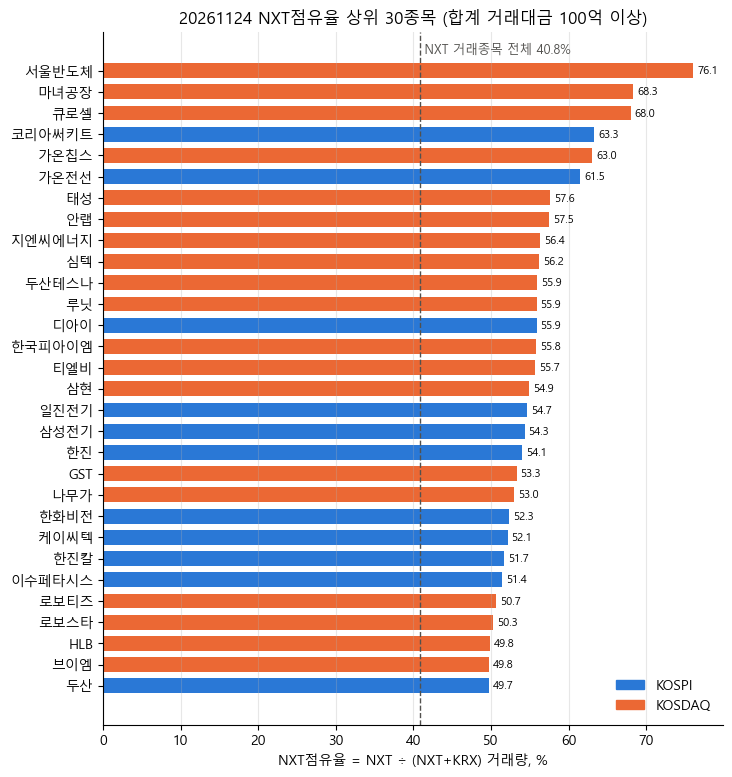

In [10]:
top = liquid.sort_values("NXT점유율(%)", ascending=False).head(30).iloc[::-1]
all_share = summ.query("모집단 == 'NXT 거래종목' and 시장 == '합계'")["NXT점유율(%)"].iloc[0]
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(top["종목명"], top["NXT점유율(%)"], color=[MKT_COLOR[m] for m in top["시장"]], height=0.7)
ax.axvline(all_share, color="#52514e", ls="--", lw=1)
ax.text(all_share, len(top) - 0.3, f" NXT 거래종목 전체 {all_share:.1f}%", fontsize=9, color="#52514e", va="bottom")
for y, v in enumerate(top["NXT점유율(%)"]):
    ax.text(v + 0.5, y, f"{v:.1f}", va="center", fontsize=8)
ax.set_xlabel("NXT점유율 = NXT ÷ (NXT+KRX) 거래량, %"); ax.grid(axis="x", alpha=.3)
ax.set_title(f"{DAY} NXT점유율 상위 30종목 (합계 거래대금 {krw(MIN_VALUE)} 이상)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=MKT_COLOR[m], label=m) for m in MARKETS], loc="lower right", frameon=False)
plt.show()

## 5. 분포 — 대부분의 종목은 어디쯤인가
종목별 NXT점유율 분포입니다. 시장 합계 점유율은 거래가 많은 대형주가 끌고 가므로, 전형적인 종목은 중앙값으로 봅니다.

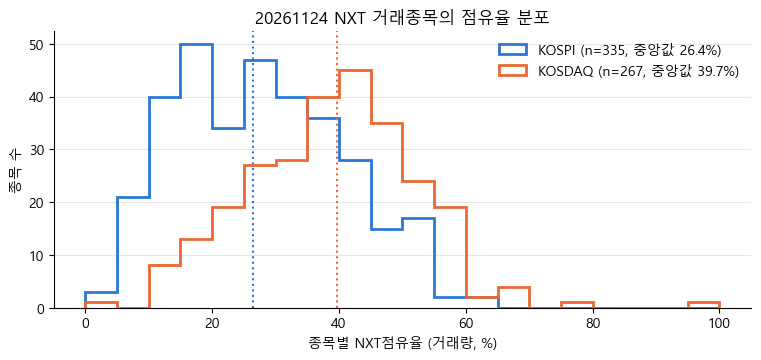

NXT 거래량이 KRX보다 많은 종목(NXT/KRX > 100%): 72개 / 602개


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 101, 5)
for m in MARKETS:
    v = both.loc[both["시장"] == m, "NXT점유율(%)"].dropna()
    ax.hist(v, bins=bins, histtype="step", lw=2, color=MKT_COLOR[m], label=f"{m} (n={len(v)}, 중앙값 {v.median():.1f}%)")
    ax.axvline(v.median(), color=MKT_COLOR[m], ls=":", lw=1.5)
ax.set_xlabel("종목별 NXT점유율 (거래량, %)"); ax.set_ylabel("종목 수"); ax.grid(axis="y", alpha=.3)
ax.legend(frameon=False); ax.set_title(f"{DAY} NXT 거래종목의 점유율 분포")
plt.show()

over = both[both["NXT/KRX(%)"] > 100]
print(f"NXT 거래량이 KRX보다 많은 종목(NXT/KRX > 100%): {len(over)}개 / {len(both)}개")

## 6. 확인할 것 — 거래가 없거나 한쪽에서 막힌 종목
NXT `거래가능 = 거래불가`(투자경고·위험, 거래정지 등)인 종목과, 어느 한쪽 거래량이 0인 종목입니다.
이런 종목은 점유율이 0% 또는 100% 근처로 나오므로 해석에서 빼는 편이 낫습니다.

In [12]:
odd = both[(both["NXT거래가능"] != "전체") | (both["NXT거래량"] == 0) | (both["KRX거래량"] == 0)]
odd[["코드", "종목명", "시장", "NXT거래가능", "NXT거래불가사유", "NXT거래량", "KRX거래량", "NXT점유율(%)"]].reset_index(drop=True)

,코드,종목명,시장,NXT거래가능,NXT거래불가사유,NXT거래량,KRX거래량,NXT점유율(%)
0,181710,NHN,KOSPI,거래불가,투자경고/위험,0.0,437546,0.0


## 결과 읽는 법과 한계
- **"NXT 거래종목" 기준 점유율**이 원본 앱의 숫자(NXT/KRX)를 점유율로 바꾼 것입니다. 언론 보도의 "NXT 비중"은 보통 이 모집단입니다.
  "시장 전체" 기준은 NXT가 거래하지 않는 종목의 KRX 거래까지 분모에 넣어서 훨씬 낮습니다. 코스닥은 NXT 비대상 소형주 거래가 많아 차이가 큽니다.
- **거래량 기준과 거래대금 기준이 다릅니다.** NXT 거래종목은 대체로 대형·고가주라서, 시장 전체 기준으로는 거래대금 점유율이 거래량 점유율보다 높게 나옵니다.
- NXT 거래량은 애프터마켓(~20:00)까지 포함합니다(정규시장 스냅샷이 20:05 집계). 프리마켓(08:00~)도 같은 화면에 들어가는 것으로 보이지만
  세션별로 쪼개 확인하지는 않았습니다. KRX도 장 시작 전·마감 후 시간외 거래가 있어 "같은 시간대"끼리의 비교는 아닙니다.
  (KRX [12001] 거래량에 시간외·대량매매가 어디까지 들어가는지도 이 노트북에서 따로 확인하지 않았습니다.)
- NXT 거래대금에는 대량·바스켓매매 대금이 빠져 있습니다(화면에 거래대금 필드가 없음). 대량매매는 드물어(2026-08-03~11-24 조회 결과 0건) 영향은 작습니다.
- `closing_price`(종가매매)는 체결된 종목만 나오므로, 목록에 없는 종목의 종가매매 거래량은 0으로 둡니다.
- KRX `all_stock_price`는 휴장일을 넣으면 값이 전부 `-`로 옵니다(2026-11-22 확인). 헬퍼는 이때 오류를 냅니다. NXT는 휴장일에 0건입니다.